# MSH 3-T-junction array: Z and X gates with partial-fusion readout (TensorBinding / Julia)

Everything needed to reproduce the chain-only 3-T-junction results is collected here, in one notebook. They are the same results as the kwant notebook
`3_tjunctions_kwant.ipynb` (in this directory). The functions were originally copied from these scripts (not included here):

| Section | Source file(s) |
|---|---|
| basics: σ matrices, exact diagonal MPO, dense conversion | `msh_chain.jl`, `msh_chain_majorana.jl` |
| hopping matrix, MPS Majorana localization | `msh_trijunction.jl` |
| array geometry, MPO and dense reference | `msh_tjunction_array.jl` |
| exchange_12 protocol | `msh_tjunction_braid.jl`, `msh_tjunction_array_braid.jl` |
| logical gate from the braid matrix | `msh_logical_gate.jl` |
| exchange_23 protocol, moving Hamiltonian, exact Majoranas | `msh_exchange23.jl` |
| fusion protocol, ΔQ | `msh_zgate_fusion.jl`, `msh_xgate_fusion.jl` |
| MPS route (DMRG zero modes, inverse-iteration refinement, TDVP) | `msh_chain_majorana.jl`, `msh_trijunction.jl`, TensorBinding `evolve_with_tdvp_timedep` |
| export for the kwant check | `export_tb_reference.jl` |

One change from the scripts: `dense_H` here adds the exchange blocks to a precomputed $J = 0$ matrix, where the scripts call
`array_reference` at every step. The result is identical (checked below) and much faster.

## Model

Chain sites only (as in V5: `d = 0` with cutouts deletes the substrate). The horizontal chain is $y = 0$, $x = -48\dots47$, with T-junctions at $x_c = -32, 0, 32$
and vertical legs $y = 1\dots16$. Nambu basis $(c_\uparrow, c_\downarrow, c^\dagger_\uparrow, c^\dagger_\downarrow)$, $H_{\rm BdG} = [[H_0, \Delta i\sigma_y], [(\Delta i\sigma_y)^\dagger, -H_0^*]]$,
$H_0 = -\mu + J\,\mathbf S\cdot\boldsymbol\sigma$ on sites, $c^\dagger_{r+\hat d}\,(-t + i\alpha(d_x\sigma_y - d_y\sigma_x))\,c_r$ on bonds; $t=1$, $\mu=-7$, $\alpha=0.9$, $\Delta=2.4$, $J=5.8$.
Texture: $\theta = (-1)^{x+y}\tfrac{\pi}{2}f$, $\phi = \theta_{\rm arm} + \pi/2$; $f = 0$ topological ($\mathbf S\parallel\hat z$), $f = 1$ trivial (in-plane AFM).

## Results: Julia/TensorBinding vs kwant V6

The two codes build the same Hamiltonian: $\|H_{\rm kwant} - H_{\rm TensorBinding}\| = 6\times10^{-16}$ at four points of the protocols. The TensorBinding MPO matches the dense model to $\sim10^{-12}$.

| Quantity | Julia / TensorBinding | kwant V6 |
|---|---|---|
| MZM positions $x$ | −46.6, −17.5, 16.5, 45.6 | −46.6, −17.5, 16.5, 45.6 |
| first state above the MZMs (junction-2 bound state) | 0.127 | 0.127 |
| exchange_12 once: relative phase | 90.718° | 90.718° |
| Z = exchange_12 × 2: relative phase / leak | 181.44° / 2e-6 | 181.436° / 2e-6 |
| fusion ΔQ after Z / no gate / adiabatic | −0.4777 / −0.4774 / −0.4769 | −0.4777 / −0.4774 / −0.4769 |
| X (rot_Tx = 100): leak (A, B) / ΔQ | 0.108, 0.093 / +0.444 | 0.108, 0.093 / +0.444 |
| X (rot_Tx = 400): θ / P(0→1) / leak / ΔQ | 174.94° / 0.99805 / 3.4e-5 / +0.4770 | 174.94° / 0.99805 / 3.4e-5 / +0.4770 |

The last section of this notebook recomputes the Julia column and prints it next to the kwant values.

In [1]:
using LinearAlgebra, Printf, Random, Plots
using ITensors, ITensorMPS
using TensorBinding
# include(joinpath(@__DIR__, "src", "TensorBinding.jl"))
# using .TensorBinding
const TB = TensorBinding
const RUN_MPS  = true     # DMRG zero-mode check of the initial setup (~4 min)
const RUN_TDVP = false    # TDVP of exchange_12 on the MPO (slow; the exact evolution below is the reference)

false

## 1. Basics

In [2]:
const σ0 = ComplexF64[1 0; 0 1];  const σx = ComplexF64[0 1; 1 0]
const σy = ComplexF64[0 -im; im 0]; const σz = ComplexF64[1 0; 0 -1]

# Exact diagonal MPO diag(v) on the position qubits (TT-SVD, no QTCI).
# sites[1] is the most significant bit, so reverse Julia's column-major order.
function diag_mpo_exact(v::AbstractVector, pos; cutoff=1e-14)
    L = length(pos)
    A = permutedims(reshape(ComplexF64.(v), ntuple(_ -> 2, L)), L:-1:1)
    ψ = MPS(A, pos; cutoff=cutoff)
    W = MPO(pos, "Id")
    for k in 1:L
        s = pos[k]
        δ = ITensor(ComplexF64, s, s', dag(s''))   # δ(s, s', s'') copies the amplitude onto the diagonal
        for j in 1:2; δ[s => j, s' => j, s'' => j] = 1; end
        W[k] = ψ[k] * δ
        W[k] = replaceprime(W[k], 2 => 0; tags=tags(s))
    end
    return W
end

# Dense matrix / vector of an MPO / MPS: index big-endian over `sites`
function dense(mpo, sites)
    T = ITensors.@disable_warn_order prod(mpo)
    D = prod(dim.(sites))
    return reshape(Array(T, reverse(prime.(sites))..., reverse(sites)...), D, D)
end
dense_vec(ψ, sites) = vec(Array(ITensors.@disable_warn_order(prod(ψ)), reverse(sites)...))

# hopping c†_{r+d} h c_r along the unit bond d (kwant hop_x for d = x̂, hop_y for d = ŷ)
hop_matrix(t, α, d) = -t * σ0 + im * α * (d[1] * σy - d[2] * σx)

hop_matrix (generic function with 1 method)

## 2. Geometry and the TensorBinding MPO

MPO sites `[nambu; spin; cell; pos_1 … pos_L; arm]`. Each cell is a lattice T: arm 1 runs right from the junction site,
arm 2 left from $x_c - 1$, arm 3 up from $y = 1$, with $2^L$ sites per arm. Neighbouring cells are joined by one horizontal bond.

In [3]:
Base.@kwdef struct TArray
    L::Int = 4
    ncell::Int = 3
end
Ncell(a::TArray) = 2^a.L
const ARM_ANG = (0.0, π, π/2)                         # right, left, up
const ARM_ORIG = ((0.0, 0.0), (-1.0, 0.0), (0.0, 1.0))
center_x(a::TArray, c) = (c - (a.ncell + 1) / 2) * 2Ncell(a)
array_pos(a::TArray, c, s, n) = (center_x(a, c), 0.0) .+ ARM_ORIG[s] .+ n .* (cos(ARM_ANG[s]), sin(ARM_ANG[s]))
array_spin(a::TArray, f) = (c, s, n) -> begin
    x, y = round.(Int, array_pos(a, c, s, n))
    θ = (-1)^(x + y) * (π/2) * f(c, s, n); φ = ARM_ANG[s] + π/2
    (cos(φ) * sin(θ), sin(φ) * sin(θ), cos(θ))
end

"""
    msh_tjunction_array(a, f; t, μ, α, Δ, J) -> (H_BdG::MPO, sites)
"""
function msh_tjunction_array(a::TArray, f; t=1.0, μ=-7.0, α=0.9, Δ=2.4, J=5.8, cutoff=1e-13)
    L, N, nc = a.L, Ncell(a), a.ncell
    ns, ss, cl = TB.nambu_index(), TB.spin_index(), Index(nc, "Cell")
    pos, arm = siteinds("Qubit", L), TB.tjunction_index()
    term(Mpos, σmat, Bcell, Barm) =
        TB.prepend_op(TB.prepend_op(TB.postpend_op(Mpos, arm, Barm), cl, Bcell), ss, σmat)
    P(d, i) = (m = zeros(d, d); m[i, i] = 1.0; m)
    E(d, i, j) = (m = zeros(d, d); m[i, j] = 1.0; m)         # |i⟩⟨j|
    Ic, I3, Id = Matrix(1.0I, nc, nc), Matrix(1.0I, 3, 3), MPO(pos, "Id")
    Ku, Kd = TB.shift_pair_mpos(pos, 1; cyclic=false)

    terms = MPO[term(-μ * Id, σ0, Ic, I3)]
    for s in 1:3                                              # intra-arm hopping, every cell
        h = hop_matrix(t, α, (cos(ARM_ANG[s]), sin(ARM_ANG[s])))
        push!(terms, term(Ku, h, Ic, P(3, s)), term(Kd, Matrix(h'), Ic, P(3, s)))
    end
    P0 = TB._site_projector_mpo(L, pos, 0)                     # junction bonds (left → center, up → center)
    for (a_, b_, d) in ((2, 1, (1.0, 0.0)), (1, 2, (-1.0, 0.0)), (3, 1, (0.0, -1.0)), (1, 3, (0.0, 1.0)))
        push!(terms, term(P0, hop_matrix(t, α, d), Ic, E(3, b_, a_)))
    end
    Pend = TB._site_projector_mpo(L, pos, N - 1)               # inter-cell: right end of c → left end of c+1
    h = hop_matrix(t, α, (1.0, 0.0))
    for c in 1:nc-1
        push!(terms, term(Pend, h, E(nc, c + 1, c), E(3, 2, 1)),
                     term(Pend, Matrix(h'), E(nc, c, c + 1), E(3, 1, 2)))
    end
    S = array_spin(a, f)                                       # exchange, per cell and arm
    for c in 1:nc, s in 1:3, (k, σ) in enumerate((σx, σy, σz))
        v = [J * S(c, s, n)[k] for n in 0:N-1]
        maximum(abs, v) > 1e-14 && push!(terms, term(diag_mpo_exact(v, pos), σ, P(nc, c), P(3, s)))
    end
    H0 = +(terms...; cutoff)

    Hp  = term(Δ * Id, ComplexF64[0 1; -1 0], Ic, I3)
    Hpd = swapprime(dag(Hp), 0, 1)
    HB  = +(TB.prepend_nambu(H0, ns, :Pp), TB.prepend_nambu(-1.0 * dag(H0), ns, :Ph),
            TB.prepend_nambu(Hp, ns, :tp), TB.prepend_nambu(Hpd, ns, :tm); cutoff)
    return HB, [ns; ss; cl; pos; arm]
end

"""Independent dense BdG matrix from site coordinates only (nearest neighbours |Δr| = 1)."""
function array_reference(a::TArray, f; t=1.0, μ=-7.0, α=0.9, Δ=2.4, J=5.8)
    N, nc = Ncell(a), a.ncell; S = array_spin(a, f); M = 3N * nc
    idx(c, s, n) = (c - 1) * 3N + 3n + s                       # cell ⊗ pos ⊗ arm, arm fastest
    allsites = [(c, s, n, array_pos(a, c, s, n)) for c in 1:nc for s in 1:3 for n in 0:N-1]
    H0 = zeros(ComplexF64, 2M, 2M)
    blk(i) = [i, M + i]
    for (c, s, n, r) in allsites
        i = idx(c, s, n); Sn = S(c, s, n)
        H0[blk(i), blk(i)] .+= -μ * σ0 + J * (Sn[1] * σx + Sn[2] * σy + Sn[3] * σz)
        for (c2, s2, n2, r2) in allsites
            d = r2 .- r
            abs(hypot(d...) - 1) < 1e-9 && (H0[blk(idx(c2, s2, n2)), blk(i)] .+= hop_matrix(t, α, d))
        end
    end
    D = kron(Δ * ComplexF64[0 1; -1 0], Matrix(1.0I, M, M))
    return [H0 D; D' -conj(H0)]
end

"""Exchange J S·σ (particle σ, hole −σ*) of the given cells only, as a BdG MPO on `sites`."""
function array_exchange_mpo(a::TArray, sites, f, cells; J=5.8, cutoff=1e-14)
    ns, ss, cl, pos, arm = sites[1], sites[2], sites[3], sites[4:end-1], sites[end]
    S = array_spin(a, f); N = Ncell(a); H = nothing
    for c in cells, s in 1:3, (k, σ) in enumerate((σx, σy, σz))
        v = [J * S(c, s, n)[k] for n in 0:N-1]
        maximum(abs, v) > 1e-14 || continue
        Pc = zeros(a.ncell, a.ncell); Pc[c, c] = 1.0
        Pa = zeros(3, 3); Pa[s, s] = 1.0
        D = TB.prepend_op(TB.postpend_op(diag_mpo_exact(v, pos), arm, Pa), cl, Pc)
        m = +(TB.prepend_nambu(TB.prepend_op(D, ss, σ), ns, :Pp),
              TB.prepend_nambu(TB.prepend_op(D, ss, -conj(σ)), ns, :Ph); cutoff)
        H = isnothing(H) ? m : +(H, m; cutoff)
    end
    return H
end

"""Exchange blocks of texture f added in place to a dense matrix (dense ordering of array_reference)."""
function add_exchange_dense!(H, a::TArray, f; J=5.8)
    N, nc = Ncell(a), a.ncell; M = 3N * nc; S = array_spin(a, f)
    for c in 1:nc, s in 1:3, n in 0:N-1
        i = (c - 1) * 3N + 3n + s; Sn = S(c, s, n)
        m = J * (Sn[1] * σx + Sn[2] * σy + Sn[3] * σz)
        for α in 1:2, β in 1:2
            H[(α-1)*M + i, (β-1)*M + i] += m[α, β]
            H[2M + (α-1)*M + i, 2M + (β-1)*M + i] -= conj(m[α, β])
        end
    end
    return H
end

"""Diagonal position operator r·û on [nambu; spin; cell; pos; arm]."""
function array_position_mpo(a::TArray, sites; β=0.05)
    ns, ss, cl, pos, arm = sites[1], sites[2], sites[3], sites[4:end-1], sites[end]
    u = (cos(β), sin(β)); X = nothing
    for c in 1:a.ncell, s in 1:3
        Pc = zeros(a.ncell, a.ncell); Pc[c, c] = 1.0
        Pa = zeros(3, 3); Pa[s, s] = 1.0
        v = [sum(array_pos(a, c, s, n) .* u) for n in 0:Ncell(a)-1]
        m = TB.prepend_op(TB.postpend_op(diag_mpo_exact(v, pos), arm, Pa), cl, Pc)
        X = isnothing(X) ? m : +(X, m; cutoff=1e-14)
    end
    return TB.prepend_op(TB.prepend_op(X, ss, σ0), ns, σ0)
end

# per-site weight (Nambu and spin summed) of a dense vector → array [arm, n, cell]
array_weight(v, a::TArray) = dropdims(sum(abs2, reshape(v, 3, Ncell(a), a.ncell, 2, 2); dims=(4, 5)); dims=(4, 5))

array_weight (generic function with 1 method)

## 3. Protocols

V5's `exchange_12`, `exchange_23` and `fuse_56` formulas are kept for $L_1 = L_2 = 14$ and mapped onto the 16-site legs:
* **exchange_12** on cell 1: arm 1 $n \leftrightarrow i = L_1 + 1 + n$; arm 2 $n \leftrightarrow i = L_1 - n$ ($n = 15$ follows $i = 0$); arm 3 $n \leftrightarrow k = \min(n, L_2)$.
* **exchange_23** on cell 2: right arm $i = 3L_1 + 3 + n$; the left arm's 16 sites are mapped linearly onto $i = 3L_1 + 2 \dots 2L_1 + 3$; up $k = \min(n, L_2)$.
* **fusion** of pair A on cell 1: both halves turn trivial from their outer ends inward, keeping $2L_p + 1$ topological sites around the junction.

Initial setup `f0`: cells 1 and 3 horizontal topological, cell 2 and all legs trivial. That gives 4 MZMs: $\gamma_1, \gamma_2$ (cell 1) and $\gamma_3, \gamma_4$ (cell 3).

In [4]:
cz_smoothstep(τ) = τ <= 0 ? 0.0 : τ >= 1 ? 1.0 : sin(π * τ / 2)^2
const f0 = (c, s, n) -> (c == 2 || s == 3) ? 1.0 : 0.0

# ── exchange_12 (rot_Tz = 200, step_Tz = 0.1) ──
Base.@kwdef struct Exchange12
    L1::Int = 14
    L2::Int = 14
    rot_T::Float64 = 200.0      # V5 rot_Tz
    step_T::Float64 = 0.1       # V5 step_Tz
end
duration(p::Exchange12) = (p.step_T * (4p.L1 + 2p.L2 + 8) + 1) * p.rot_T   # V5's t0z cuts off the last rotation

function f_horizontal(p::Exchange12, i, t)
    τ, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2
    ss = cz_smoothstep
    0 <= i <= L1     && return ss(τ - s * (i + L1 + L2 + 2)) - ss(τ - s * (L1 - i + 3L1 + 2L2 + 8))
    i == L1 + 1      && return 0.0
    L1 + 2 <= i <= 2L1 + 2 && return ss(τ - s * (2L1 + 2 - i)) - ss(τ - s * (i + L1 + L2 + 2))
    return 1.0
end
function f_vertical(p::Exchange12, k, t)
    τ, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2
    ss = cz_smoothstep
    return 1 - ss(τ - s * (k + L1 + 2)) + ss(τ - s * (L2 - k + 3L1 + L2 + 5))
end
f_braid(p::Exchange12, t) = (s, n) -> s == 1 ? f_horizontal(p, p.L1 + 1 + n, t) :
                                      s == 2 ? f_horizontal(p, max(p.L1 - n, 0), t) :
                                               f_vertical(p, min(n, p.L2), t)
f_array_braid(a::TArray, p::Exchange12, f0, t) = (c, s, n) -> c == 1 ? f_braid(p, t)(s, n) : f0(c, s, n)

# ── exchange_23 (rot_Tx = 100, step_Tx = 0.1) ──
Base.@kwdef struct Exchange23
    L1::Int = 14
    L2::Int = 14
    rot_T::Float64 = 100.0      # V5 rot_Tx
    step_T::Float64 = 0.1       # V5 step_Tx
end
function f_h23(p::Exchange23, i, t)
    τ, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2
    ss = cz_smoothstep
    if 2L1 + 3 <= i <= 3L1 + 3
        return 1 - ss(τ - s * (i - 2L1 - 3)) + ss(τ - s * (4L1 + 4 - i + L2 + L1 + 2))
    elseif 3L1 + 4 <= i <= 4L1 + 4
        return 1 - ss(τ - s * (4L1 + 4 - i + L2 + L1 + 1)) + ss(τ - s * (i - 3L1 - 4 + 3L2 + 2L1 + 3))
    end
    error("i = $i outside junction 2's segment")
end
f_v23(p::Exchange23, k, t) = (τ = t / p.rot_T; s = p.step_T; ss = cz_smoothstep;
                              1 - ss(τ - s * (k + p.L1 + 2)) + ss(τ - s * (p.L2 - k + 3p.L1 + p.L2 + 5)))
duration(p::Exchange23) = (p.step_T * (p.L1 + 3p.L2 + 2p.L1 + 3) + 1) * p.rot_T
f_cell2_23(p::Exchange23, t) = (s, n) -> s == 1 ? f_h23(p, 3p.L1 + 3 + n, t) :
                                         s == 2 ? f_h23(p, (3p.L1 + 2) - (p.L1 - 1) * n / (p.L1 + 1), t) :
                                                  f_v23(p, min(n, p.L2), t)
f_array_23(p::Exchange23, f0, t) = (c, s, n) -> c == 2 ? f_cell2_23(p, t)(s, n) : f0(c, s, n)

# ── partial fusion of pair A (rot_T0 = 100, step_T0 = 0.2, Lp = 1) ──
Base.@kwdef struct Fusion
    L1::Int = 14
    Lp::Int = 1
    rot_T::Float64 = 100.0      # V5 rot_T0
    step_T::Float64 = 0.2       # V5 step_T0
end
duration(q::Fusion) = ((q.L1 - q.Lp + 1) * q.step_T + 1) * q.rot_T          # V5 t0i
function f_fuse(q::Fusion, f0, t)
    ss = cz_smoothstep; τ = t / q.rot_T; N = 16
    return (c, s, n) -> begin
        c == 1 || return f0(c, s, n)
        s == 3 && return 1.0
        if s == 2
            n < q.Lp && return 0.0
            return ss(τ - q.step_T * (N - 1 - n))     # outer end (n = 15) first
        else
            n <= q.Lp && return 0.0
            return ss(τ - q.step_T * (N - 1 - n))
        end
    end
end

f_fuse (generic function with 1 method)

## 4. Time-dependent Hamiltonian and exact evolution

In [5]:
"""H(t) = H_fixed + exchange of the `moving` cells for the texture ft(t); MPO via B(t), dense via dense_H(B, t)."""
struct MovingArrayH
    a::TArray; ft::Function; moving::Vector{Int}; J::Float64
    H_fixed::MPO; sites::Vector{<:Index}; H_noex_dense::Matrix{ComplexF64}
end
function MovingArrayH(a, ft, f0, moving; J=5.8)
    H_noex, sites = msh_tjunction_array(a, f0; J=0.0)
    fixed = setdiff(1:a.ncell, moving)
    H_fixed = isempty(fixed) ? H_noex : +(H_noex, array_exchange_mpo(a, sites, f0, fixed; J); cutoff=1e-14)
    return MovingArrayH(a, ft, moving, J, H_fixed, sites, array_reference(a, f0; J=0.0))
end
(B::MovingArrayH)(t) = +(B.H_fixed, array_exchange_mpo(B.a, B.sites, B.ft(t), B.moving; J=B.J); cutoff=1e-14)
dense_H(B::MovingArrayH, t) = add_exchange_dense!(copy(B.H_noex_dense), B.a, B.ft(t); J=B.J)

# exp(−i H dt) V by Taylor series (‖H dt‖ ≈ 1.5; terms kept until < 1e-16 relative)
function expmv_taylor(H, V, dt; tol=1e-16, maxterms=80)
    out = copy(V); term = copy(V)
    for k in 1:maxterms
        term = (-im * dt / k) * (H * term)
        out .+= term
        norm(term) < tol * norm(out) && return out
    end
    error("Taylor series did not converge")
end

"""Midpoint-exponential evolution from t0 to t1; snapshots every dt_snap (always the last one)."""
function evolve_snap(B, V0, t0, t1, dt_snap; dt=0.1)
    nsteps = round(Int, (t1 - t0) / dt); dt = (t1 - t0) / nsteps
    every = isfinite(dt_snap) ? max(1, round(Int, dt_snap / dt)) : nsteps
    V = copy(V0); ts = [t0]; Vs = [copy(V)]
    for k in 1:nsteps
        V = expmv_taylor(dense_H(B, t0 + (k - 0.5) * dt), V, dt)
        (k % every == 0 || k == nsteps) && (push!(ts, t0 + k * dt); push!(Vs, copy(V)))
    end
    return ts, Vs
end

evolve_snap (generic function with 1 method)

## 5. Majoranas, braid matrix and logical gate

The evolution is quadratic, so the many-body unitary acts on the Majoranas as a rotation, $\hat U\hat\gamma_j\hat U^\dagger = \sum_i\hat\gamma_i M_{ij}$, with
$M_{ij} = \langle\gamma_i(0)|\gamma_j(T)\rangle$. Only $\psi_A = (\gamma_1 + i\gamma_2)/\sqrt2$ and $\psi_B = (\gamma_3 + i\gamma_4)/\sqrt2$ are evolved;
$C = \tau_x K$ commutes with $U$, so $\gamma_{2k-1}(t) = (\psi + C\psi)/\sqrt2$ and $\gamma_{2k}(t) = (\psi - C\psi)/(i\sqrt2)$.
The logical gate is the spin representation $\tilde U$ of $M$ on $|n_An_B\rangle$, restricted to $|0\rangle_L = |00\rangle$, $|1\rangle_L = |11\rangle$.

In [6]:
"""Exact zero modes of a dense H: 4 smallest |E|, localized along x, Cγ = γ, positive-energy pairing."""
function exact_majoranas(a::TArray, H0)
    N = Ncell(a); half = size(H0, 1) ÷ 2
    E, U = eigen(Hermitian(H0))
    Z = U[:, sortperm(abs.(E))[1:4]]
    xop = Diagonal(repeat([array_pos(a, c, s, n)[1] for s in 1:3, n in 0:N-1, c in 1:a.ncell][:], 4))
    Fx = eigen(Hermitian(Z' * xop * Z))
    Cd(v) = vcat(conj(v[half+1:end]), conj(v[1:half]))
    γ0 = [(g = Z * Fx.vectors[:, j]; g * exp(im * angle(dot(g, Cd(g))) / 2)) for j in 1:4]
    for k in (1, 3)
        ψ = (γ0[k] + im * γ0[k+1]) / √2
        real(dot(ψ, H0 * ψ)) < 0 && (γ0[k+1] = -γ0[k+1])
    end
    return γ0, Fx.values
end

function majoranas_from_modes(V)
    half = size(V, 1) ÷ 2
    C(v) = vcat(conj(v[half+1:end]), conj(v[1:half]))
    γ = Vector{ComplexF64}[]
    for j in 1:size(V, 2)
        ψ = V[:, j]
        push!(γ, (ψ + C(ψ)) / √2, (ψ - C(ψ)) / (im * √2))
    end
    return γ
end
braid_matrix4(γ0, VT) = (γT = majoranas_from_modes(VT); [dot(γ0[i], γT[j]) for i in 1:4, j in 1:4])
leak4(γ0, VT) = [1 - sum(abs2(dot(g, VT[:, j])) for g in γ0) for j in 1:size(VT, 2)]

# Majorana operators on the 2-fermion Fock space, basis |n_A n_B⟩ ordered 00, 01, 10, 11
function jw_majoranas()
    a = ComplexF64[0 1; 0 0]
    Z = ComplexF64[1 0; 0 -1]; I2 = Matrix{ComplexF64}(I, 2, 2)
    fA, fB = kron(a, I2), kron(Z, a)
    return [fA + fA', -im * (fA - fA'), fB + fB', -im * (fB - fB')]
end

"""Spin representation Ũ of the rotation M (orthogonalized first): Ũ γ̂_j Ũ† = Σ_i γ̂_i M_ij."""
function logical_unitary(M)
    F = svd(real.(M)); Mo = F.U * F.Vt
    det(Mo) > 0 || error("M has det −1: not a parity-preserving rotation")
    γ = jw_majoranas()
    best = nothing
    for sgn in (1, -1)
        A = real.(log(Mo)); A = (A - A') / 2
        G = sum(sgn * A[i, j] * γ[i] * γ[j] for i in 1:4, j in 1:4) / 4
        U = exp(G)
        res = maximum(norm(U * γ[j] * U' - sum(γ[i] * Mo[i, j] for i in 1:4)) for j in 1:4)
        (best === nothing || res < best[2]) && (best = (U, res))
    end
    return best
end

"""Even-sector logical block of Ũ, its rotation angle θ and axis n̂ (UL/√det = cos θ/2 − i sin θ/2 n̂·σ)."""
function logical_even_block(Ũ)
    UL = Ũ[[1, 4], [1, 4]]
    W = UL / sqrt(det(UL))
    θ = 2acos(clamp(real(tr(W)) / 2, -1, 1))
    σs = (ComplexF64[0 1; 1 0], ComplexF64[0 -im; im 0], ComplexF64[1 0; 0 -1])
    n̂ = [real(im * tr(σ * W)) / (2sin(θ / 2)) for σ in σs]
    return (; UL, θ, n̂)
end

logical_even_block (generic function with 1 method)

## 6. Fusion readout

$|0\rangle$ and $|1\rangle$ share the bulk and differ in the occupation of both fermions, so
$\Delta Q = Q(U|1\rangle) - Q(U|0\rangle) = \sum_{k=A,B}\langle\psi_k|\tau_z|\psi_k\rangle$ (electron number; charge is $-e\,\Delta Q$).

In [7]:
τz_dense(D) = vcat(ones(D ÷ 2), -ones(D ÷ 2))
ΔQ_modes(V) = (τ = τz_dense(size(V, 1)); [real(dot(V[:, k], τ .* V[:, k])) for k in 1:size(V, 2)])
function δn_modes(V, a::TArray)
    w = zeros(3, Ncell(a), a.ncell)
    for k in 1:size(V, 2)
        A = reshape(V[:, k], 3, Ncell(a), a.ncell, 2, 2)              # (arm, n, cell, spin, nambu)
        w .+= dropdims(sum(abs2, A[:, :, :, :, 1]; dims=4) .- sum(abs2, A[:, :, :, :, 2]; dims=4); dims=4)
    end
    return w
end
"""Instantaneous adiabatic ΔQ of the +E members of the two lowest pairs (splitting below 1e-11 → 0)."""
function ΔQ_adiabatic(H)
    D = size(H, 1); τ = τz_dense(D)
    E, U = eigen(Hermitian(H))
    o = sortperm(abs.(E))[1:4]
    pos = o[E[o] .> 0]
    sum((abs(E[i]) < 1e-11 ? 0.0 : real(dot(U[:, i], τ .* U[:, i]))) for i in pos; init=0.0), sort(abs.(E[o]))[[1, 3]]
end

ΔQ_adiabatic (generic function with 1 method)

## 7. MPS route (TensorBinding)

These functions find the zero modes and evolve them without dense matrices:
* DMRG on $K = H^2 + \eta^2$ for the near-zero subspace, plus one extra state as a gap check.
* One inverse-iteration step $(H - \sigma)^{-1}$, which removes the bulk admixture that $\Delta Q$ is sensitive to.
* Localization with the position operator, and TDVP for the time evolution.

In [8]:
norm_Hψ(H, ψ) = norm(orthogonalize(apply(H, ψ; alg="naive", truncate=false), 1)[1])

function zero_mode_subspace(HB, sites; nzero=2, η=1e-2, seed=1234,
                            nsweeps=20, maxdim=[10, 20, 50, 100, 200], cutoff=1e-14, cutoff_K=1e-14,
                            noise=[1e-6, 1e-7, 1e-8, 0.0], weight=10.0,
                            eigsolve_krylovdim=20, eigsolve_maxiter=3)
    # ITensor's default local Krylov dimension (3) stalls on K; eigsolve_krylovdim = 20 converges.
    K = TB.build_K(HB, sites, 0.0, η; cutoff_K)   # TB default cutoff_K = 1e-8 drops η²
    Random.seed!(seed)
    ψs = MPS[]
    for k in 1:nzero+1
        ψ0 = random_mps(sites; linkdims=10)
        _, ψ = isempty(ψs) ? dmrg(K, ψ0; nsweeps, maxdim, cutoff, noise, eigsolve_krylovdim,
                                  eigsolve_maxiter, outputlevel=0) :
                             dmrg(K, ψs, ψ0; weight, nsweeps, maxdim, cutoff, noise,
                                  eigsolve_krylovdim, eigsolve_maxiter, outputlevel=0)
        push!(ψs, ψ / norm(ψ))
    end
    ψgap = pop!(ψs)
    return ψs, [norm_Hψ(HB, ψ) for ψ in ψs], norm_Hψ(HB, ψgap)
end

# The local GMRES solves of (H − σ)x = ψ rarely converge at the KrylovKit defaults (krylovdim = 30) and each one warns;
# verbosity = 0 silences that. krylovdim = 60 converges them (‖Hψ‖ 2e-5 → 3e-8) but takes ~2.5× longer.
refine_subspace(HB, ψs; σ=1e-3, nsweeps=6, cutoff=1e-20, maxdim=200, krylovdim=30) =
    [(x = ITensorMPS.linsolve(HB, ψ, ψ, -σ, 1.0; nsweeps, cutoff, maxdim,
                              updater_kwargs=(; krylovdim, verbosity=0)); x / norm(x)) for ψ in ψs]

function localize_majoranas(HB, sites, ψs, X; cutoff=1e-14)
    ns = sites[1]
    S  = [inner(a, b) for a in ψs, b in ψs]
    Xm = [inner(a', X, b) for a in ψs, b in ψs]
    F  = eigen(Hermitian((Xm + Xm') / 2), Hermitian((S + S') / 2))
    comb(c) = (γ = c[1] * ψs[1]; for j in 2:length(ψs); γ = +(γ, c[j] * ψs[j]; cutoff); end; γ / norm(γ))
    τx = ITensor([0.0 1.0; 1.0 0.0], ns', ns)
    C(ψ) = (φ = dag(ψ); φ[1] = noprime(τx * φ[1]); φ)
    fix(γ) = exp(im * angle(inner(γ, C(γ))) / 2) * γ
    γs = [fix(comb(F.vectors[:, i])) for i in 1:length(ψs)]
    return (; γs, centers = F.values, Hγ = [inner(a', HB, b) for a in γs, b in γs], C)
end

localize_majoranas (generic function with 1 method)

## 8. Export for the kwant check (`tb_reference/`, read by `3_tjunctions_kwant.ipynb`)

In [9]:
function export_tb_reference(a::TArray; out="tb_reference")
    mkpath(out); N = Ncell(a)
    open(joinpath(out, "coords.txt"), "w") do io
        for c in 1:a.ncell, n in 0:N-1, s in 1:3
            x, y = round.(Int, array_pos(a, c, s, n)); println(io, x, " ", y)
        end
    end
    cases = [("initial", f0),
             ("z_t1020", f_array_braid(a, Exchange12(), f0, 1020.0)),
             ("x100_t485", f_array_23(Exchange23(rot_T=100.0), f0, 485.0)),
             ("fuse_t300", f_fuse(Fusion(), f0, 300.0))]
    for (name, f) in cases
        open(joinpath(out, name * ".bin"), "w") do io; write(io, array_reference(a, f)); end
    end
    return out
end

export_tb_reference (generic function with 1 method)

## 9. Runs

### Checks: MPO vs dense, fast `dense_H` vs `array_reference`, initial MZMs

In [10]:
a = TArray(L=4, ncell=3); N = Ncell(a)
HB, sites = msh_tjunction_array(a, f0)
R = array_reference(a, f0)
Cd = kron(σx, Matrix(1.0I, size(R, 1) ÷ 2, size(R, 1) ÷ 2))
@printf("D = %d, χ(H) = %d, ‖H_MPO − H_dense‖ = %.1e, PH ‖C H* C + H‖ = %.1e\n",
        size(R, 1), maxlinkdim(HB), norm(dense(HB, sites) - R), norm(Cd * conj(R) * Cd + R))

p12, p23, q = Exchange12(), Exchange23(), Fusion()
for (lbl, ft, mov, t) in (("exchange_12", t -> f_array_braid(a, p12, f0, t), [1], 1020.0),
                          ("exchange_23", t -> f_array_23(p23, f0, t), [2], 485.0),
                          ("fusion",      t -> f_fuse(q, f0, t), [1], 300.0))
    B = MovingArrayH(a, ft, f0, mov)
    @printf("%-12s t = %4.0f: ‖H_MPO(t) − H_dense(t)‖ = %.1e, ‖dense_H − array_reference‖ = %.1e, χ = %d\n",
            lbl, t, norm(dense(B(t), B.sites) - array_reference(a, ft(t))),
            norm(dense_H(B, t) - array_reference(a, ft(t))), maxlinkdim(B(t)))
end

E = eigvals(Hermitian(R)); Ea = sort(abs.(E))
γ0, xc = exact_majoranas(a, R)
V0 = hcat((γ0[1] + im * γ0[2]) / √2, (γ0[3] + im * γ0[4]) / √2)
@printf("MZMs at x = %s, |E| ≤ %.1e, next state %.4f\n", string(round.(xc, digits=1)), Ea[4], Ea[5])
println("exported to ", export_tb_reference(a))

D = 576, χ(H) = 18, ‖H_MPO − H_dense‖ = 3.5e-12, PH ‖C H* C + H‖ = 0.0e+00
exchange_12  t = 1020: ‖H_MPO(t) − H_dense(t)‖ = 4.3e-10, ‖dense_H − array_reference‖ = 0.0e+00, χ = 22


exchange_23  t =  485: ‖H_MPO(t) − H_dense(t)‖ = 2.0e-09, ‖dense_H − array_reference‖ = 0.0e+00, χ = 21
fusion       t =  300: ‖H_MPO(t) − H_dense(t)‖ = 1.9e-11, ‖dense_H − array_reference‖ = 0.0e+00, χ = 21


MZMs at x = [-46.6, -17.5, 16.5, 45.6], |E| ≤ 1.2e-09, next state 0.1270
exported to 

tb_reference


In [11]:
if RUN_MPS
    tz = time()
    ψs, E_sub, E_gap = zero_mode_subspace(HB, sites; nzero=4)
    ψs = refine_subspace(HB, ψs; σ=1e-3)
    loc = localize_majoranas(HB, sites, ψs, array_position_mpo(a, sites))
    tz = time() - tz
    Z = eigen(Hermitian(R)).vectors[:, sortperm(abs.(E))[1:4]]
    @printf("MPS (%.0f s): ‖Hψ‖ ≤ %.1e before refinement, gap-check state %.3f, weight in the exact subspace ≥ %.12f\n",
            tz, maximum(E_sub), E_gap, minimum(norm(Z' * dense_vec(γ, sites))^2 for γ in loc.γs))
    println("MPS Majorana centers r·û (β = 0.05): ", round.(loc.centers, digits=1))
end

┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 1.20e-02
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136
┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 1.28e-04
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136


┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 1.20e-04
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136
┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 6.81e-05
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136


┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 1.53e-05
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136
┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 9.06e-09
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136


┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 9.57e-12
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136
┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 1.38e-05
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136


┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 6.18e-05
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136
┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 1.06e-04
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136


...

┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 5.72e-06
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136
┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 2.54e-05
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136


┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 2.44e-05
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136
┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 2.31e-05
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136


MPS (253 s): ‖Hψ‖ ≤ 2.0e-05 before refinement, gap-check state 0.127, weight in the exact subspace ≥ 0.999999999611
MPS Majorana centers r·û (β = 0.05): 

┌ Warning: GMRES linsolve stopped without converging after 100 iterations:
│ * norm of residual = 2.01e-05
│ * number of operations = 2903
└ @ KrylovKit ~/.julia/packages/KrylovKit/bEE7W/src/linsolve/gmres.jl:136


[-46.5, -17.5, 16.5, 45.5]


### Z gate: exchange_12 twice on junction 1, then partial fusion (and fusion with no gate)

In [12]:
function gate_and_fusion(kind; rot_Tx=100.0, q=Fusion())
    if kind === :Z
        p = Exchange12(); T1 = duration(p); fg = t -> f_array_braid(a, p, f0, t < T1 ? t : t - T1); mov = [1]
    elseif kind === :X
        p = Exchange23(rot_T=rot_Tx); T1 = duration(p); fg = t -> f_array_23(p, f0, t < T1 ? t : t - T1); mov = [1, 2]
    else
        T1 = 0.0; fg = t -> f0; mov = [1]
    end
    Tg = 2T1; Tf = duration(q)
    ft = t -> t < Tg ? fg(t) : f_fuse(q, f0, t - Tg)
    B = MovingArrayH(a, ft, f0, mov)
    res = Dict{Symbol,Any}(:T1 => T1, :Tg => Tg)
    V = V0
    if Tg > 0
        _, V1 = evolve_snap(B, V0, 0.0, T1, Inf)
        _, V2 = evolve_snap(B, V1[end], T1, Tg, Inf)
        for (key, VT) in ((:one, V1[end]), (:two, V2[end]))
            M = real.(braid_matrix4(γ0, VT))
            Ũ, r = logical_unitary(M)
            L = logical_even_block(Ũ)
            res[key] = (; M, Ũ, L, leak = leak4(γ0, VT), phase = rad2deg(mod(angle(L.UL[2, 2] / L.UL[1, 1]), 2π)),
                         P01 = abs2(Ũ[4, 1]))
        end
        V = V2[end]
    end
    ts, Vs = evolve_snap(B, V, Tg, Tg + Tf, Tf / 80)
    HT = dense_H(B, Tg + Tf)
    ΔQad, Ep = ΔQ_adiabatic(HT)
    Ev, Uv = eigen(Hermitian(HT)); Zs = Uv[:, sortperm(abs.(Ev))[1:4]]
    res[:fusion] = (; ΔQ = sum(ΔQ_modes(Vs[end])), ΔQpair = ΔQ_modes(Vs[end]), ΔQad, Ep,
                     leak = [1 - norm(Zs' * Vs[end][:, k])^2 for k in 1:2],
                     ts = ts .- Tg, ΔQt = [sum(ΔQ_modes(V)) for V in Vs], δn = δn_modes(Vs[end], a))
    return res
end

tZ = time(); rZ = gate_and_fusion(:Z); tZ = time() - tZ
rF = gate_and_fusion(:none)
@printf("Z (%.0f s): exchange_12 once: phase %.4f°, leak %s;  twice: phase %.4f°, leak %s, P(0→1) = %.1e\n",
        tZ, rZ[:one].phase, string(round.(rZ[:one].leak, sigdigits=3)), rZ[:two].phase,
        string(round.(rZ[:two].leak, sigdigits=3)), rZ[:two].P01)
for (lbl, r) in (("Z + fusion", rZ), ("fusion only", rF))
    f = r[:fusion]
    @printf("%-12s ΔQ = %+.6f (A %+.6f, B %+.1e), adiabatic %+.6f, |E_A| = %.4f, leak %s\n",
            lbl, f.ΔQ, f.ΔQpair..., f.ΔQad, f.Ep[2], string(round.(f.leak, sigdigits=3)))
end

Z (124 s): exchange_12 once: phase 90.7180°, leak [9.73e-7, 3.44e-15];  twice: phase 181.4359°, leak [2.0e-6, -6.66e-16], P(0→1) = 8.6e-27
Z + fusion   ΔQ = -0.477719 (A -0.477719, B +3.8e-08), adiabatic -0.476854, |E_A| = 0.0439, leak [3.69e-5, -2.22e-15]


fusion only  ΔQ = -0.477373 (A -0.477373, B +3.8e-08), adiabatic -0.476854, |E_A| = 0.0439, leak [3.78e-5, -5.33e-15]


### X gate: exchange_23 twice through junction 2 (rot_Tx = 100 and 400), then partial fusion

In [13]:
rX = Dict{Float64,Any}()
for rot in (100.0, 400.0)
    tX = time(); rX[rot] = gate_and_fusion(:X; rot_Tx=rot); tX = time() - tX
    r = rX[rot][:two]; f = rX[rot][:fusion]
    @printf("X rot_Tx = %.0f (%.0f s): leak %s, θ = %.3f° about n̂ = %s, P(0→1) = %.6f; fusion ΔQ = %+.6f (A %+.6f, B %+.1e)\n",
            rot, tX, string(round.(r.leak, sigdigits=3)), rad2deg(r.L.θ), string(round.(r.L.n̂, digits=4)),
            r.P01, f.ΔQ, f.ΔQpair...)
end

X rot_Tx = 100 (61 s): leak [0.108, 0.0928], θ = 179.245° about n̂ = [1.0, -0.0, -0.0], P(0→1) = 0.999957; fusion ΔQ = +0.443864 (A +0.411503, B +3.2e-02)
X rot_Tx = 400 (219 s): leak [3.42e-5, 3.49e-5], θ = 174.939° about n̂ = [1.0, -0.0, -0.0], P(0→1) = 0.998051; fusion ΔQ = +0.477005 (A +0.476113, B +8.9e-04)


In [14]:
if RUN_TDVP          # TDVP of ψ_A through one exchange_12 on the MPO, compared with the exact evolution
    p = Exchange12(); T1 = duration(p)
    B = MovingArrayH(a, t -> f_array_braid(a, p, f0, t), f0, [1])
    toMPS(v) = MPS(permutedims(reshape(v, Tuple(dim.(B.sites))[end:-1:1]), length(B.sites):-1:1), B.sites; cutoff=1e-15)
    nsteps = round(Int, T1 / 0.1); dt = T1 / nsteps
    sA = TB.evolve_with_tdvp_timedep(t -> B(t), toMPS(V0[:, 1]), nsteps, dt;
                                     maxdim=64, cutoff=1e-20, tol=1e-12, krylovdim=30, reverse_step=true)
    _, Vex = evolve_snap(B, V0[:, 1:1], 0.0, T1, Inf)
    @printf("TDVP vs exact after exchange_12: ‖ψ_TDVP − ψ_exact‖ = %.1e\n", norm(dense_vec(sA[end], B.sites) - Vex[end][:, 1]))
end

### Summary: Julia (this notebook) vs kwant V6

quantity                  Julia       kwant V6
S phase                  90.718         90.718


Z phase                 181.436        181.436
Z leak A             1.9962e-06          2e-06
ΔQ Z+fusion           -0.477719      -0.477719
ΔQ fusion only        -0.477373      -0.477373
ΔQ adiabatic          -0.476854      -0.476854
X100 leak A            0.108426       0.108426
X100 leak B            0.092757       0.092757
ΔQ X100+fusion         0.443864       0.443864
X400 θ                  174.939        174.939
X400 P(0→1)            0.998051       0.998051
X400 leak A         3.41647e-05       3.42e-05
ΔQ X400+fusion         0.477005       0.477005


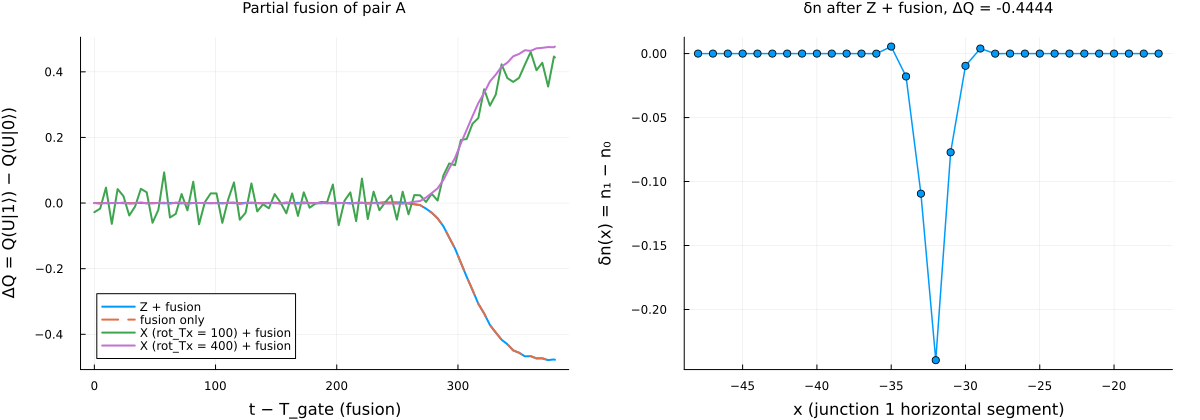

In [15]:
kwant = Dict("S phase" => 90.718, "Z phase" => 181.436, "Z leak A" => 2e-6, "ΔQ Z+fusion" => -0.477719,
             "ΔQ fusion only" => -0.477373, "ΔQ adiabatic" => -0.476854,
             "X100 leak A" => 0.1084264, "X100 leak B" => 0.092757, "ΔQ X100+fusion" => 0.443864,
             "X400 θ" => 174.9391, "X400 P(0→1)" => 0.998051, "X400 leak A" => 3.42e-5, "ΔQ X400+fusion" => 0.477005)
julia = Dict("S phase" => rZ[:one].phase, "Z phase" => rZ[:two].phase, "Z leak A" => rZ[:two].leak[1],
             "ΔQ Z+fusion" => rZ[:fusion].ΔQ, "ΔQ fusion only" => rF[:fusion].ΔQ, "ΔQ adiabatic" => rF[:fusion].ΔQad,
             "X100 leak A" => rX[100.0][:two].leak[1], "X100 leak B" => rX[100.0][:two].leak[2],
             "ΔQ X100+fusion" => rX[100.0][:fusion].ΔQ, "X400 θ" => rad2deg(rX[400.0][:two].L.θ),
             "X400 P(0→1)" => rX[400.0][:two].P01, "X400 leak A" => rX[400.0][:two].leak[1],
             "ΔQ X400+fusion" => rX[400.0][:fusion].ΔQ)
@printf("%-16s %14s %14s\n", "quantity", "Julia", "kwant V6")
for k in ["S phase", "Z phase", "Z leak A", "ΔQ Z+fusion", "ΔQ fusion only", "ΔQ adiabatic",
          "X100 leak A", "X100 leak B", "ΔQ X100+fusion", "X400 θ", "X400 P(0→1)", "X400 leak A", "ΔQ X400+fusion"]
    @printf("%-16s %14.6g %14.6g\n", k, julia[k], kwant[k])
end

gr()
p1 = plot(xlabel="t − T_gate (fusion)", ylabel="ΔQ = Q(U|1⟩) − Q(U|0⟩)", legend=:bottomleft,
          title="Partial fusion of pair A", titlefontsize=10)
for (lbl, r, ls) in (("Z + fusion", rZ, :solid), ("fusion only", rF, :dash),
                     ("X (rot_Tx = 100) + fusion", rX[100.0], :solid), ("X (rot_Tx = 400) + fusion", rX[400.0], :solid))
    plot!(p1, r[:fusion].ts, r[:fusion].ΔQt; lw=2, ls, label=lbl)
end
f = rZ[:fusion]
xs = [array_pos(a, 1, 2, n)[1] for n in 15:-1:0]; append!(xs, [array_pos(a, 1, 1, n)[1] for n in 0:15])
δx = vcat([f.δn[2, n+1, 1] for n in 15:-1:0], [f.δn[1, n+1, 1] for n in 0:15])
p2 = plot(xs, δx; marker=:circle, lw=1.5, xlabel="x (junction 1 horizontal segment)", ylabel="δn(x) = n₁ − n₀",
          legend=false, title=@sprintf("δn after Z + fusion, ΔQ = %.4f", sum(δx)), titlefontsize=10)
plot(p1, p2; layout=(1, 2), size=(1200, 420), margin=5Plots.mm)